# HW #2: Exploratory Data Analysis of International Coastal Cleanup Data

In [1]:
# load in the packages you will need for your analysis

import pandas as pd  # pandas is a package for data analysis and manipulation
import seaborn as sns  # seaborn is a data visualization package, works on top of matplotlib
import matplotlib.pyplot as plt # matplotlib is the OG python plotting library and really useful for formatting 
import cartopy as cart # cartopy is a package designed for visualizing data by making maps

In [2]:
# Assistant
# Set the path to the correct directory for your particular computer
# Use raw string (r"") to prevent backslashes from being interpreted as escape characters
infile = r"C:\Users\talia\OneDrive - Old Dominion University\Documents\Old Dominion\Environmental Data Science\Data\International_Coastal_Cleanup.csv"

# read in the .csv file with the column separator explicitly defined
data = pd.read_csv(infile, sep = ',',low_memory = False)

In [3]:
# Print the entire dataframe
print(data)

                                    Area        Date Cigarette Butts  \
0                  Ocean View Beach Park  10/27/2023              40   
1                          Lakewood Park  10/21/2023              20   
2                        Plum Point Park   10/8/2023               7   
3   Lafayette Park & Lavalette Boat Ramp   10/7/2023             220   
4                           Barraud Park   10/7/2023             800   
..                                   ...         ...             ...   
72             Sarah Constant Beach Park   9/30/2016               0   
73                SPOT- Military Gardens   9/30/2016              63   
74    Tidewater (Little Creek - Bayview)   9/30/2016              56   
75             Wetland (Poppe and Somee)   9/30/2016             111   
76                       Willoughby Spit   9/30/2016             386   

   Food Wrappers (candy, chips, etc.)  Take Out/Away Containers (Plastic)  \
0                                   0                     

Printing the entire data frame allows us to see the dataset as if I had just opened it as a CSV file and looked at it. I can see the row numbers on the left hand side of the frame, the column headers on top, and then the associated values within each column. This is mostly useful for an overall visual, nothing quantitative.

In [4]:
# Print the information about the data in the dataframe

data.info()

<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 53 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Area                                       77 non-null     str    
 1   Date                                       77 non-null     str    
 2   Cigarette Butts                            77 non-null     str    
 3   Food Wrappers (candy, chips, etc.)         77 non-null     str    
 4   Take Out/Away Containers (Plastic)         77 non-null     int64  
 5   Take Out/Away Containers (Foam)            77 non-null     int64  
 6   Bottle Caps (Plastic)                      77 non-null     int64  
 7   Bottle Caps (Metal)                        77 non-null     str    
 8   Lids (Plastic)                             77 non-null     int64  
 9   Straws, Stirrers                           77 non-null     int64  
 10  Forks, Knives, Spoons                  

By calling upon "info", we see the dataframe broken down into column header, the number of rows associated with each column, and what type of data is stored in each column. Here we can see that the first two columns are area and date information and the rest are different types of trash found during the various cleanups. There are 77 rows per column. The data types are a mix of string (str), integer (int64), and float (float64). This dataset has some numeric data that is actually stored as a string (i.e. Cigarette Butts), which could cause issues when trying to perform calculations with that data.

In [4]:
# Print the shape of the data
# nrows, ncols

data.shape

(77, 53)

The data "shape" output tells us that there are 77 rows and 53 columns in this dataframe.

In [5]:
# Print the total number of datapoints in the dataframe
# ncol * nrows

data.size

4081

The data "size" output just multiplies the number of rows by the number of columns to tell us how many cells there are where data is stored in this frame, which is 4081.

In [6]:
# Print a list of the column names in the dataframe

data.columns

Index(['Area', 'Date', 'Cigarette Butts', 'Food Wrappers (candy, chips, etc.)',
       'Take Out/Away Containers (Plastic)', 'Take Out/Away Containers (Foam)',
       'Bottle Caps (Plastic)', 'Bottle Caps (Metal)', 'Lids (Plastic)',
       'Straws, Stirrers', 'Forks, Knives, Spoons',
       'Beverage Bottles (Plastic)', 'Beverage Bottles (Glass)',
       'Beverage Cans', 'Grocery Bags (Plastic)', 'Other Plastic Bags',
       'Paper Bags', 'Cups, Plates (Paper)', 'Cups, Plates (Plastic)',
       'Cups, Plates (Foam)', 'Fishing Buoys, Pots & Traps',
       'Fishing Net & Pieces', 'Fishing Line (1 yard/meter = 1 piece)',
       'Rope (1 yard/meter = 1 piece)', 'Fishing Gear (Clean Swell)',
       '6-Pack Holders', 'Other Plastic/Foam Packaging',
       'Other Plastic Bottles (oil, bleach, etc.)', 'Strapping Bands',
       'Tobacco Packaging/Wrap', 'Other Packaging (Clean Swell)',
       'Appliances (refrigerators, washers, etc.)', 'Balloons', 'Cigar Tips',
       'Cigarette Lighters', 'Co

The data "columns" output prints a string vector of all of the column names associated with the dataframe without the additional information from "info" or just "print".

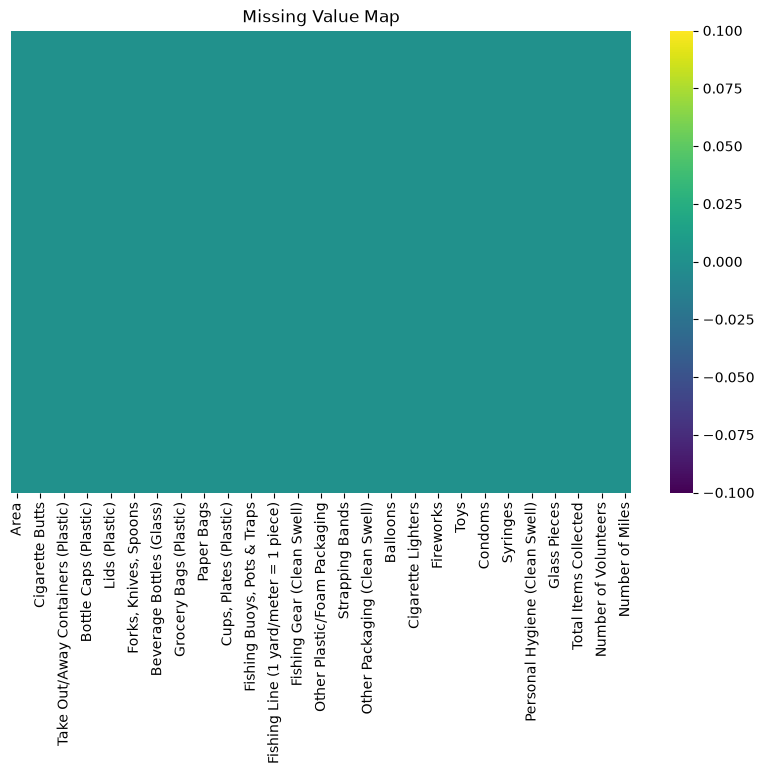

In [24]:
# Assess where there's missing data and identify any patterns

plt.figure(figsize=(10, 6))
sns.heatmap(data.isnull(), cbar=True, yticklabels=False, cmap="viridis")
plt.title("Missing Value Map")
plt.show() 

This script produces a heatmap of where any data is missing from the dataframe using MatPlotLib and Seaborn. The missing data is identified by calling "isnull". This dataset does not have any missing data, as the map is just one solid color. 

In [5]:
# Descriptive statistics for the numeric data in the dataframe
# The other data is area and date

data.describe()

,Take Out/Away Containers (Plastic),Take Out/Away Containers (Foam),Bottle Caps (Plastic),Lids (Plastic),"Straws, Stirrers","Forks, Knives, Spoons",Beverage Bottles (Plastic),Beverage Cans,Grocery Bags (Plastic),Other Plastic Bags,...,Toys,Other Trash (Clean Swell),Condoms,Diapers,Syringes,Tampons/Tampon Applicators,Foam Pieces,Number of Volunteers,Volunteer Hours,Number of Miles
count,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,...,77.000000,77.000000,77.000000,77.000000,77.00000,77.000000,77.000000,77.000000,77.00000,77.000000
mean,18.363636,13.714286,98.337662,23.350649,50.558442,13.909091,68.922078,44.350649,38.961039,36.233766,...,0.168831,18.961039,1.909091,1.259740,0.61039,0.922078,64.441558,18.896104,37.37013,1.530909
std,21.944253,18.943724,148.793093,26.738877,62.141920,20.238825,92.227089,55.825331,59.709922,77.109269,...,0.864544,67.232989,4.205829,3.743073,1.94771,2.113654,128.515767,27.249135,57.04352,1.486711
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000
25%,3.000000,1.000000,16.000000,6.000000,11.000000,1.000000,15.000000,6.000000,5.000000,2.000000,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,5.000000,9.00000,1.000000
50%,8.000000,6.000000,43.000000,13.000000,24.000000,7.000000,34.000000,26.000000,17.000000,10.000000,...,0.000000,0.000000,1.000000,0.000000,0.00000,0.000000,14.000000,11.000000,22.00000,1.000000
75%,31.000000,19.000000,107.000000,33.000000,72.000000,20.000000,70.000000,67.000000,44.000000,34.000000,...,0.000000,1.000000,2.000000,1.000000,1.00000,1.000000,58.000000,22.000000,38.00000,2.000000
max,90.000000,106.000000,780.000000,109.000000,368.000000,136.000000,395.000000,276.000000,326.000000,542.000000,...,7.000000,441.000000,33.000000,24.000000,15.00000,14.000000,750.000000,178.000000,396.00000,10.000000


"Describe" calculates descriptive statistics for all of the numeric data in the dataframe. So, for this dataset, everything except the area and date columns. The mean number of trash type found varies widely across trash types. For example, the average number of bottle caps found was ~98 with a large standard deviation of ~149, while the average number of toys found was just 0.16. This function is also helpful for identifying outliers; for example, the maximum number of bottle caps found was 780, which is more than 600 counts greater than the 3rd quartile value of 107. This dataset is quite heterogeneous.

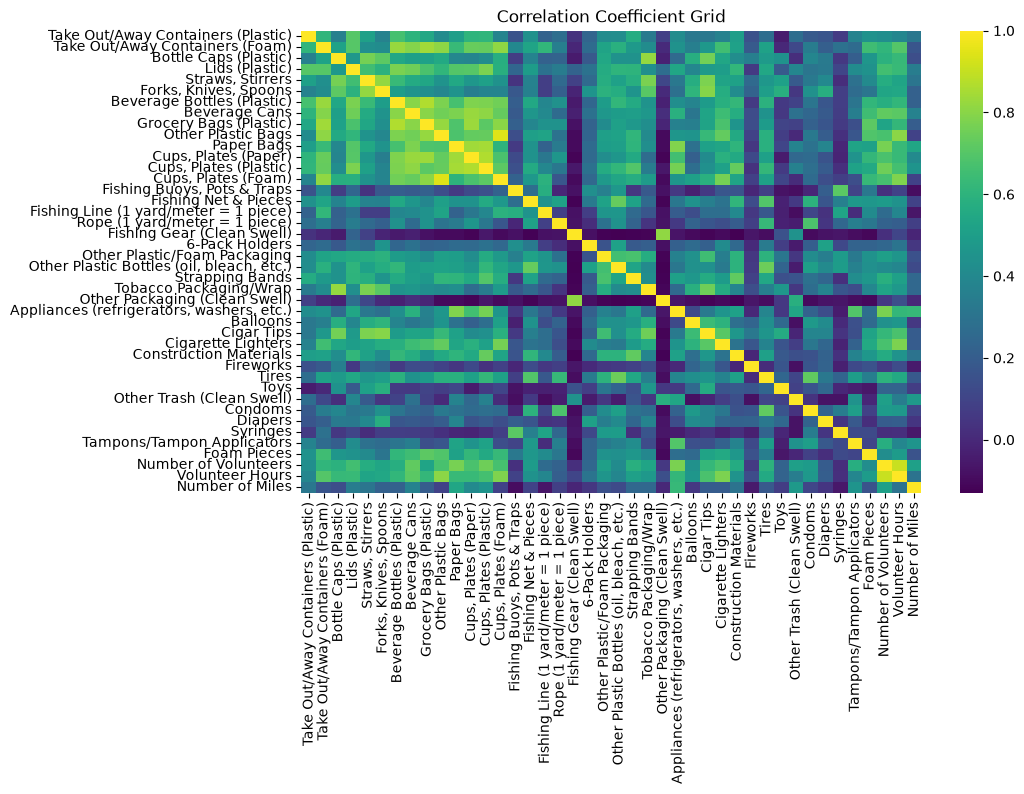

In [6]:
# Correlations between the different numeric data columns in the dataframe

corr = data.corr(numeric_only = True)

# Turn this into a heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr, cbar=True, yticklabels=True, cmap="viridis")
plt.title("Correlation Coefficient Grid")
plt.show()

This code uses the same setup as the heatmap to assess missing data, but this time to assess the correlation between different variables in the dataset, ranging from 1 (strongest positive correlation) to -1 (strongest negative correlation). One notably strong positive correlation is between "Cups, Plates (foam)" and "Other Plastic Bags", which makes sense consideration both are likely to be included in restaurant takeout. There are many strong negative correlations that likely just stem from low counts of those items - for example, fishing gear and tires.

In [7]:
# Practice some basic math
data['Straws, Stirrers'] + data['Forks, Knives, Spoons']

0       5
1      55
2      19
3      24
4     175
     ... 
72     14
73      3
74     12
75     15
76    170
Length: 77, dtype: int64

Adds together the "Straws, Stirrers" and "Forks, Knives, Spoons" column to produce a sum of straws, stirrers, and cutlery from each cleanup.

In [18]:
# Practice some basic math
allstrawsandstirrers = data['Straws, Stirrers'].sum() 
print(allstrawsandstirrers) # have to explicitly print since I defined a new variable rather just writing out a calculation

3893


Creates a new variable that sums all of the "Straws, Stirrers" counts from across all of the cleanups. The total number of straws and stirrers found across all of the different cleanups was 3,893.

In [8]:
# Practice some basic math
data['Volunteer Hours'] / data['Number of Volunteers']

0     1.0
1     2.0
2     3.0
3     2.0
4     1.5
     ... 
72    2.0
73    5.0
74    1.0
75    3.0
76    3.0
Length: 77, dtype: float64

Calculates the average number of volunteer hours per volunteer at each cleanup, without assigning it to a new variable or matrix. Most volunteers worked for between 1 and 3 hours at each event.

In [9]:
# Get a list of the unique values found in the 'Area' column of the dataframe
data['Area'].unique()

# Assign the list of unique values of 'Area' to a new variable called 'areas'
areas = data['Area'].unique()
# Print this new variable
print(areas)

<ArrowStringArray>
[                                                  'Ocean View Beach Park',
                                                           'Lakewood Park',
                                                         'Plum Point Park',
                                    'Lafayette Park & Lavalette Boat Ramp',
                                                            'Barraud Park',
                        'The Academy Of International Studies At Rosemont',
                                                       'Harbor Park (ERT)',
                                                         'Ocean View Park',
                                     'East Ocean View (1300 - 1900 Block)',
                               'Bayview Elementary/East Bayview Boulevard',
                                                      'ODU/Lamberts Point',
                                              'East Ocean View Rec Center',
                                                         'East Ocean 

Some of the areas listed in the "Areas" column are repeated (i.e. because multiple cleanups took place there), so this grabs the total number of unique areas where cleanups occurred (essentially eliminating duplicates) and assigns it to a new variable (which I uncreatively also called "areas"). While there are 77 rows in the original dataframe, there are only 36 unique locations where cleanups took place. 

In [10]:
# Group the data by a particular column
# In this case, the data is grouped by area, and I am only interested in the 'Straws, Stirrers' column

data.groupby('Area')['Straws, Stirrers'].unique()

Area
100 East Ocean View Ave                                                                              [5]
Admiral Taussig Boulevard (Granby Street - East Little Creek Boulevard)                             [17]
Barraud Park                                                               [149, 90, 368, 176, 127, 106]
Bay Dunes Drive                                                                                     [18]
Bayview Elementary/East Bayview Boulevard                                               [21, 18, 31, 26]
Beach (21st Bay Street - 30th Bay Street)                                                           [23]
Beach (Cottage Place Beach - North Beach View)                                                      [30]
Community Beach Park                                                                                [12]
Curlew Drive (Feeder Road - Light Rail Station)                                                      [0]
East Ocean View                                   

Here, all of the straws and stirrers counted at each location are summarized by location (although they haven't been summed yet, just listed out as individual counts if there are multiple). It becomes more clear here which locations were cleaned up more often. Ocean View Beach Park had the most number of cleanup events, with 7.

In [12]:
# Create a new matrix which is the sum of all straws and stirrers found at each location
SS_counts = data.groupby('Area')['Straws, Stirrers'].sum().reset_index()
print(SS_counts)

                                                 Area  Straws, Stirrers
0                             100 East Ocean View Ave                 5
1   Admiral Taussig Boulevard (Granby Street - Eas...                17
2                                        Barraud Park              1016
3                                     Bay Dunes Drive                18
4           Bayview Elementary/East Bayview Boulevard                96
5           Beach (21st Bay Street - 30th Bay Street)                23
6      Beach (Cottage Place Beach - North Beach View)                30
7                                Community Beach Park                12
8     Curlew Drive (Feeder Road - Light Rail Station)                 0
9                                     East Ocean View               133
10                East Ocean View (1300 - 1800 Block)               108
11                East Ocean View (1300 - 1900 Block)                49
12                         East Ocean View Rec Center           

Now I've created a new variable where the number of straws and stirrers found at each location are actually summed if there were multiple cleanups that occurred at that location.

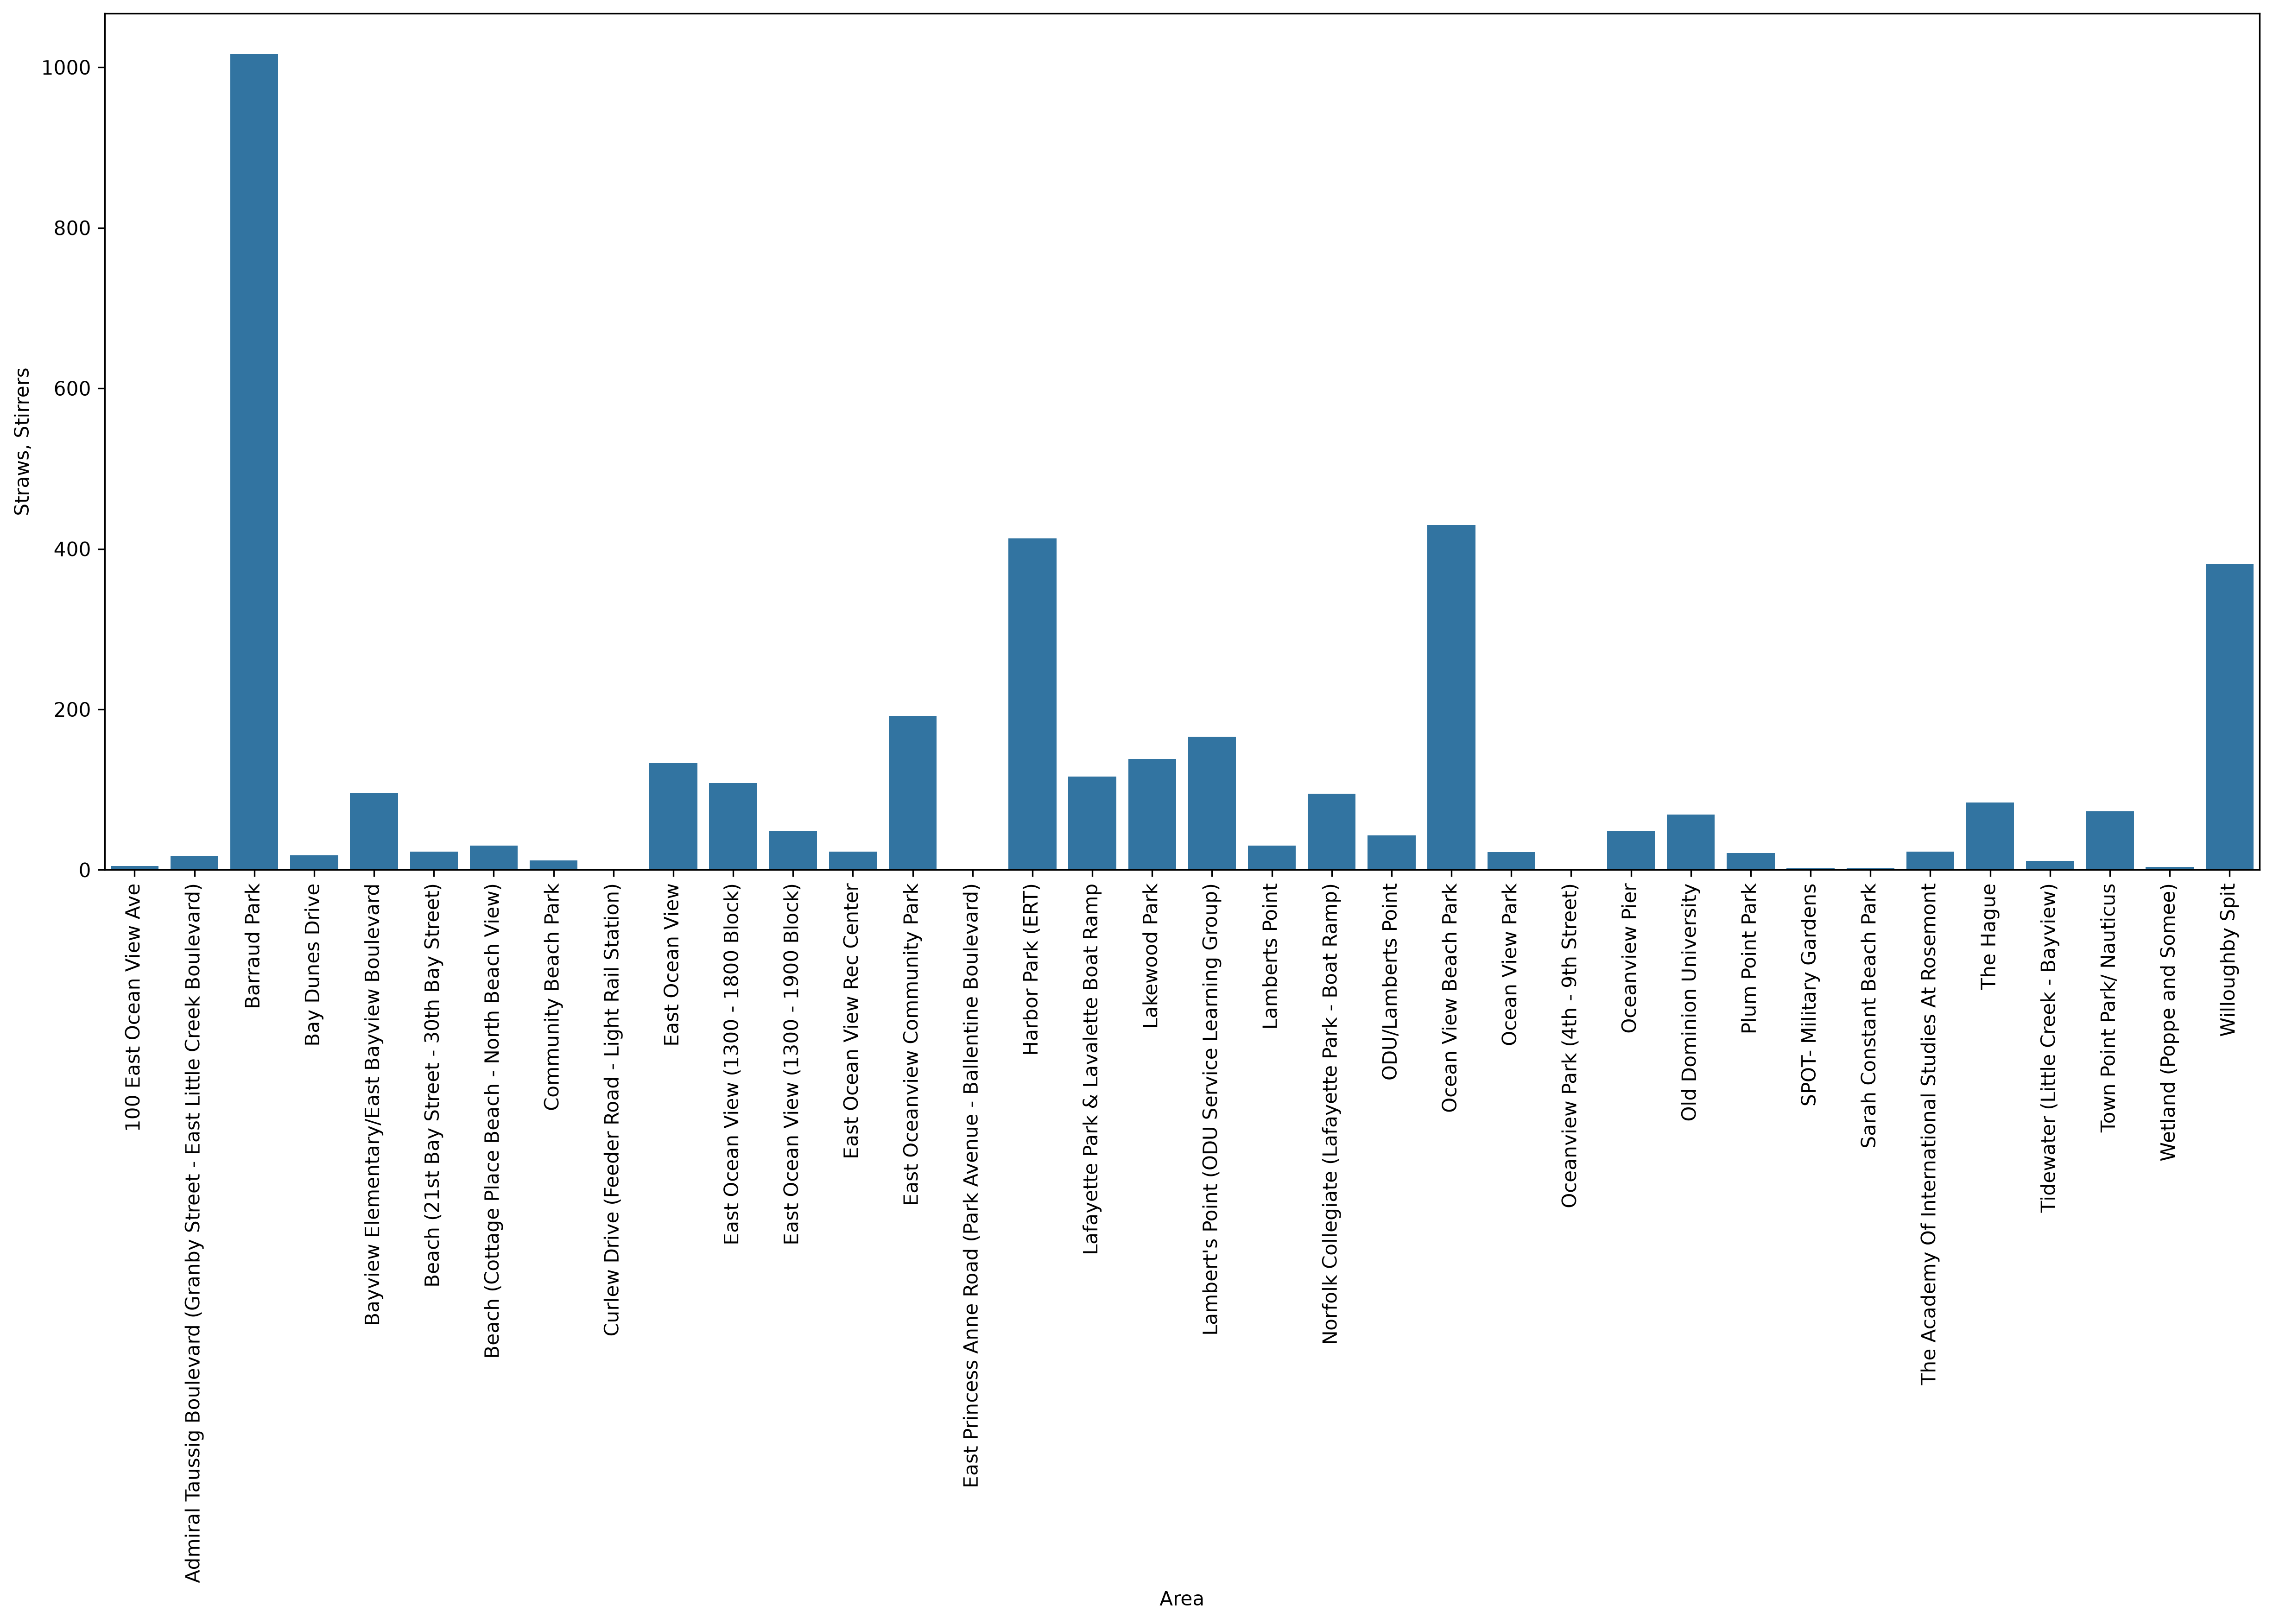

In [13]:
# Plot the data by area and how many straws and stirrers were found
fig, ax = plt.subplots(1, figsize = (20,8), dpi = 300)

sns.barplot(data = SS_counts, x = 'Area', y = 'Straws, Stirrers')
ax.tick_params(axis='x', rotation=90)

This barchart (matplotlib and seaborn again) visualizes the total number of straws and stirrers found at each location. Barraud Park by far has the most, followed by Ocean View Beach Park and then Harbor Park (ERT). When examining plots like this, though, it's useful to know information like Ocean View Beach Park was cleaned up 7 times.

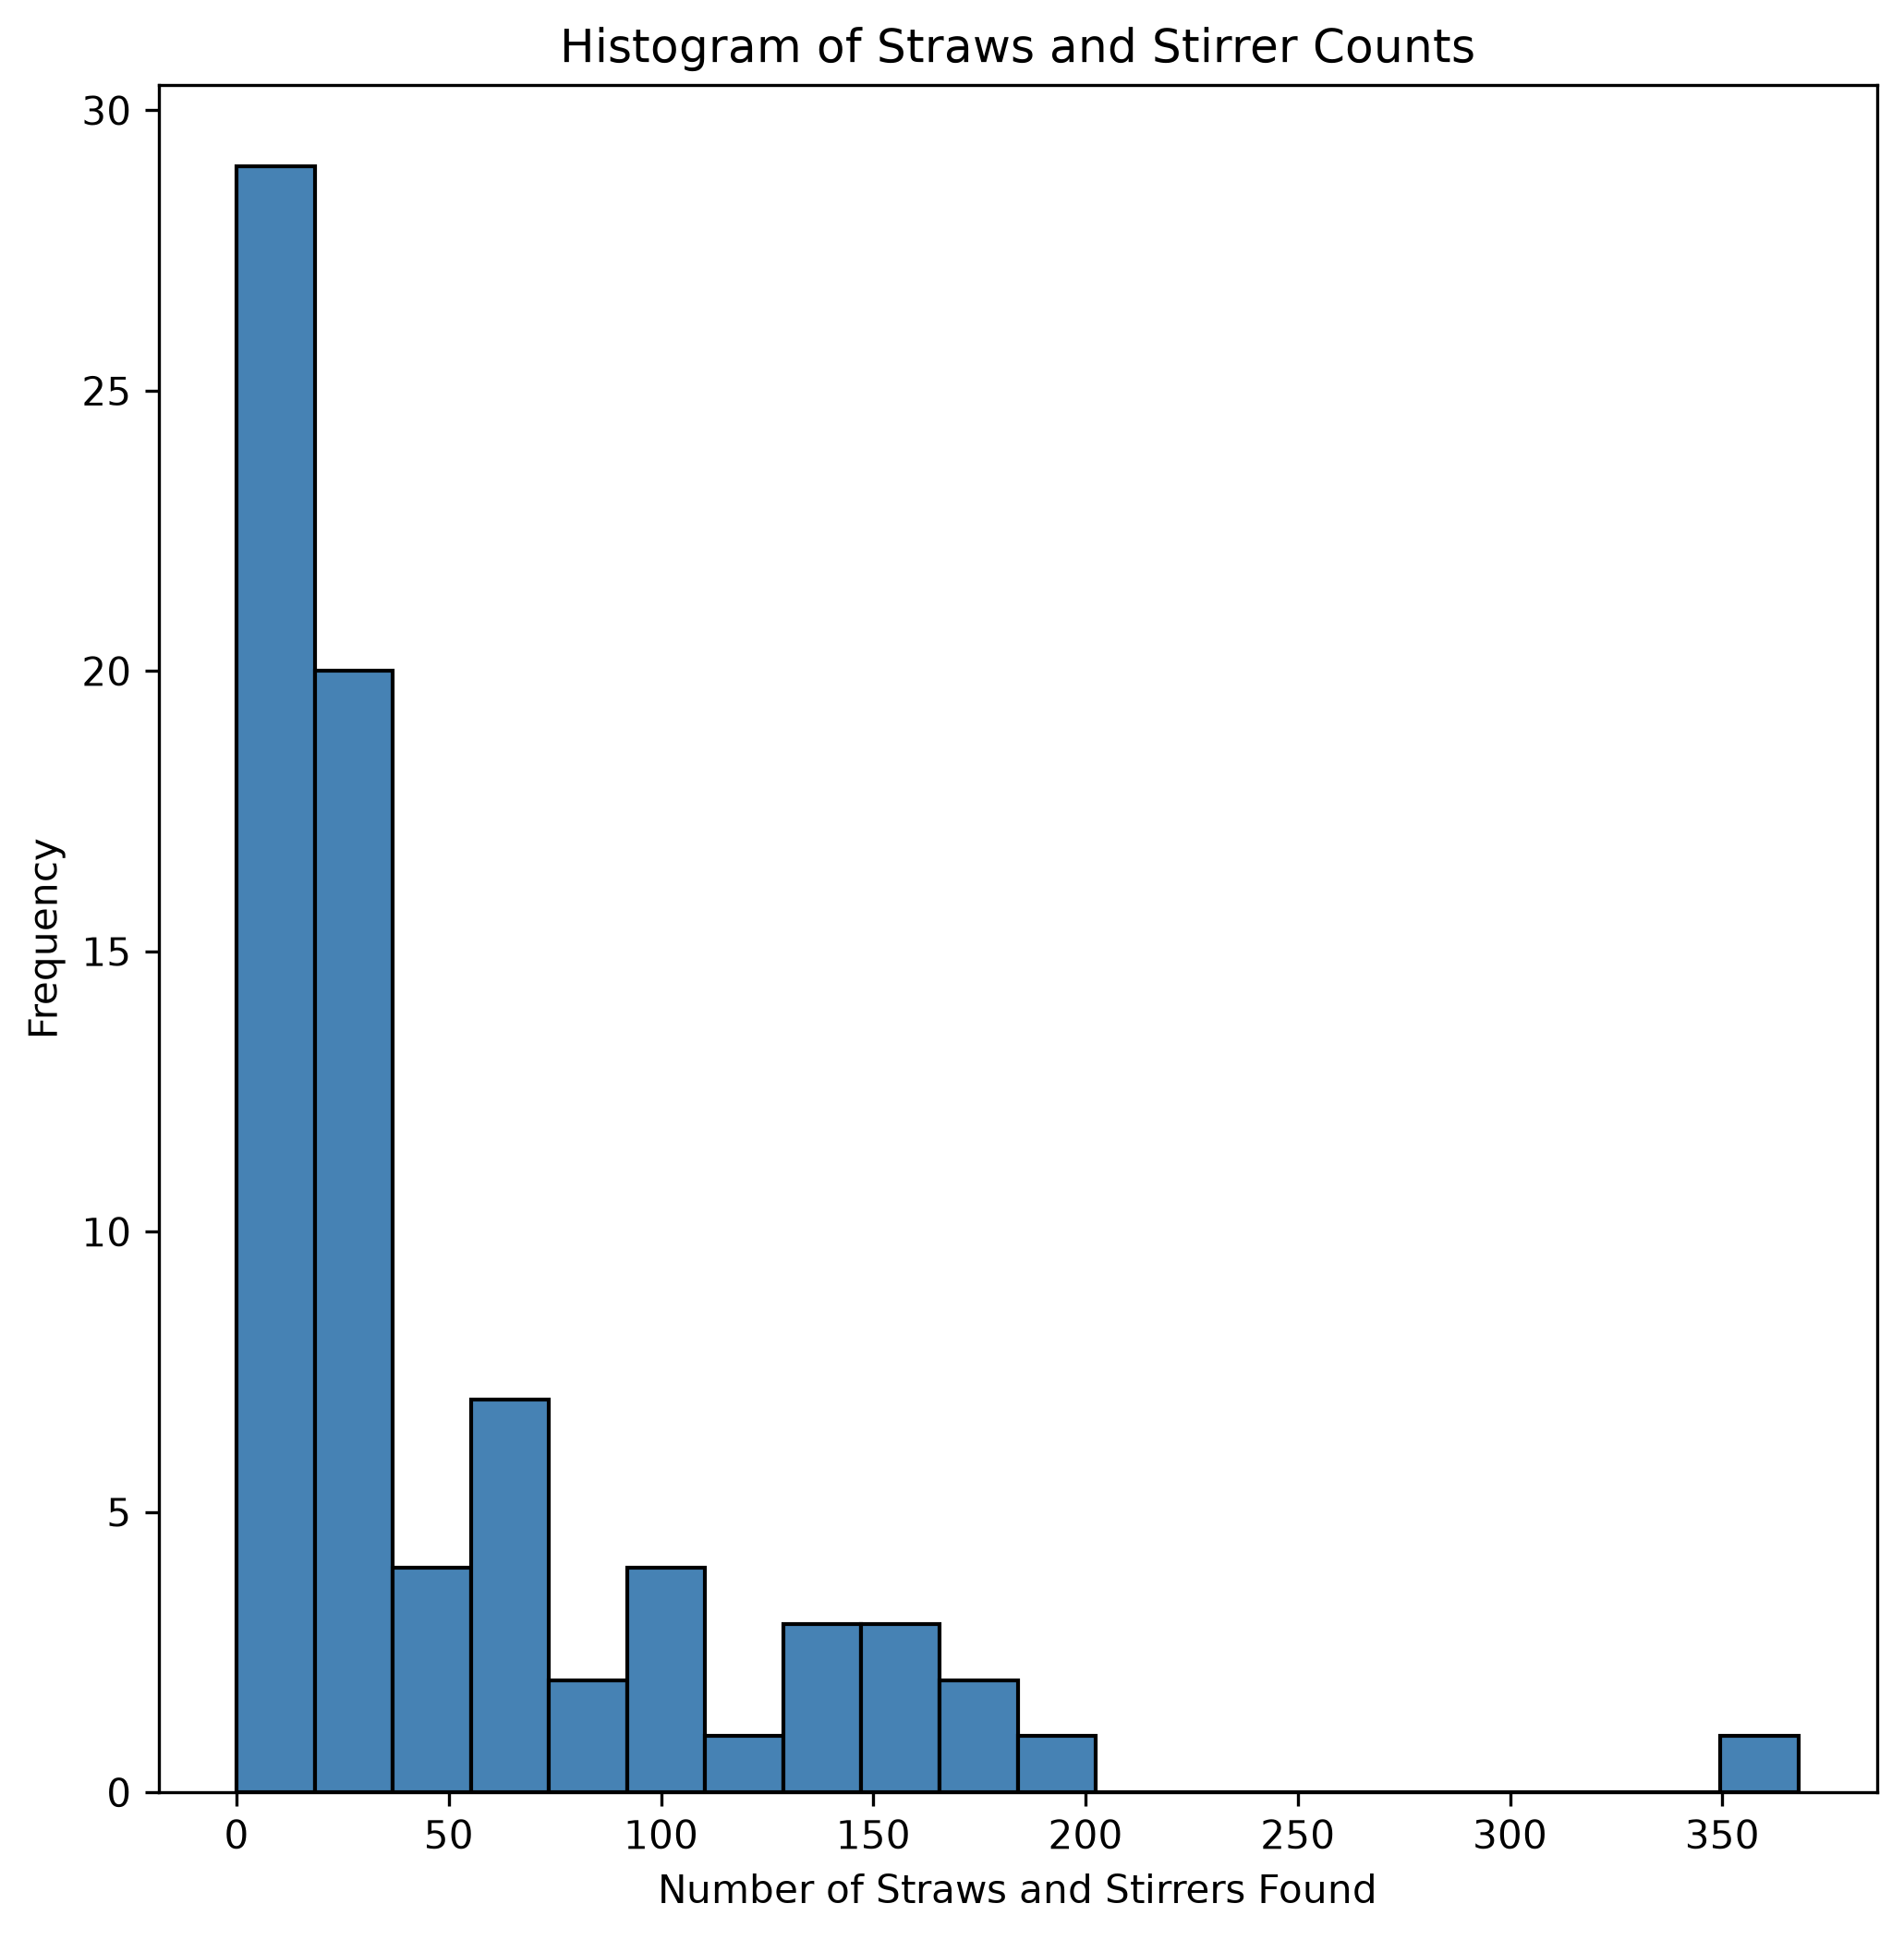

In [14]:
# Histograms are the best, fastest data "check" for single variables
# In matplotlib, this is plt.hist

fig, ax = plt.subplots(1, figsize = (8,8), dpi = 300)
plt.hist(data["Straws, Stirrers"].dropna(), bins=20, color="steelblue", edgecolor="black")
plt.title("Histogram of Straws and Stirrer Counts")
plt.xlabel("Number of Straws and Stirrers Found")
plt.ylabel("Frequency")
plt.show()

Analyzing the data by histogram gives us a better idea of how often a trash type was found across all sites. In this case, most of the time only a couple of straws and stirrers were found per cleanup event (probably between 0 and 30). The distribution of this particular trash type is extremely right skewed. 